In [95]:
# Sources:
# 1. How to use xgb in python: 
#    https://www.youtube.com/watch?v=ap2SS0-XPcE
#    https://www.youtube.com/watch?v=wqnwm15bg7A


In [96]:
# Import statements
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
from sklearn.model_selection import train_test_split

# For model evaluation
from sklearn.metrics import roc_auc_score
from sklearn.metrics import balanced_accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import brier_score_loss
from sklearn.calibration import calibration_curve

In [97]:
# Constants
FILE_IN = "./data_prepared.csv"
SAMPLE_SIZE = 10000

# Read prepared data into a pd dataframe
df_data = pd.read_csv(FILE_IN)

# Change Susceptible = 1, Resistible = 0
df_data = df_data.replace({"susceptibility": {"Susceptible": 1, "Resistant": 0}})

In [98]:
# Preparing the data for the model

# Take out a sample of the data so my computer doesn't blow up
df_sample = df_data.sample(SAMPLE_SIZE)

# Drop identifier columns
df_sample = df_sample.drop(['anon_id', 'pat_enc_csn_id_coded', 'order_proc_id_coded', 'order_time_jittered_utc'], axis=1)

# Turn the data to a table with only numerical values
data = pd.get_dummies(df_sample, drop_first=True, dtype=int)
data = data.rename(columns={'susceptibility_1': 'susceptibility'})

# Test and train data split
X_train, X_test, y_train, y_test = train_test_split(data.drop('susceptibility', axis=1), data['susceptibility'], train_size=0.8, random_state=11)

print(X_train.shape, X_test.shape)
print(y_train.shape, y_test.shape)

(8000, 148) (2000, 148)
(8000,) (2000,)


In [ ]:
# Setting the model parameters and making the model
xgb_model = xgb.XGBClassifier(
    random_state = 11, # Seed number for the randomizer in order to get same results each time
    learning_rate = 0.1, # Tells the model the weightage of every tree in xgb classifier
    n_estimators = 5000, # The model will create a maximum of 5000 trees
    subsample = 0.5 # 50% of training data will be randomly selected for creating each tree in the model (every tree will have different sample of observations, prevents overfitting)
)
test_set = [(X_test, y_test)]

xgb_model.fit(X_train,
              y_train, 
              eval_set = test_set, # What is the evaluation dataset
              verbose = True) # Show the output as the model is being trained

[0]	validation_0-logloss:0.49646
[1]	validation_0-logloss:0.49008
[2]	validation_0-logloss:0.48357
[3]	validation_0-logloss:0.47768
[4]	validation_0-logloss:0.47313
[5]	validation_0-logloss:0.46991
[6]	validation_0-logloss:0.46583
[7]	validation_0-logloss:0.46347
[8]	validation_0-logloss:0.46140
[9]	validation_0-logloss:0.45814
[10]	validation_0-logloss:0.45652
[11]	validation_0-logloss:0.45325
[12]	validation_0-logloss:0.44980
[13]	validation_0-logloss:0.44710
[14]	validation_0-logloss:0.44445
[15]	validation_0-logloss:0.44172
[16]	validation_0-logloss:0.44059
[17]	validation_0-logloss:0.43879
[18]	validation_0-logloss:0.43736
[19]	validation_0-logloss:0.43616
[20]	validation_0-logloss:0.43470
[21]	validation_0-logloss:0.43250
[22]	validation_0-logloss:0.43004
[23]	validation_0-logloss:0.42788
[24]	validation_0-logloss:0.42743
[25]	validation_0-logloss:0.42658
[26]	validation_0-logloss:0.42597
[27]	validation_0-logloss:0.42419
[28]	validation_0-logloss:0.42171
[29]	validation_0-loglos

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [103]:
# Validating the results WITH Data used in testing

# The validation data set is given to the model and see how well it performs on unseen data
y_pred = xgb_model.predict(X_test)

# ROC-AUC: Compute Area Under the Receiver Operating Characteristic Curve (ROC AUC) from prediction scores.
print("ROC-AUC: {:.4f}".format(roc_auc_score(y_test, y_pred)))

# Balanced accuracy: The balanced accuracy in binary and multiclass classification problems to deal with imbalanced datasets. It is defined as the average of recall obtained on each class.
print("Balanced accuracy: {:.4f}".format(balanced_accuracy_score(y_test, y_pred)))

# Precision score: The precision is the ratio tp / (tp + fp) where tp is the number of true positives and fp the number of false positives. The precision is intuitively the ability of the classifier not to label as positive a sample that is negative.
# The best value is 1 and the worst value is 0.
print("Precision score: {:.4f}".format(precision_score(y_test, y_pred)))

# Recall score: The recall is the ratio tp / (tp + fn) where tp is the number of true positives and fn the number of false negatives. The recall is intuitively the ability of the classifier to find all the positive samples.
# The best value is 1 and the worst value is 0.
print("Recall score: {:.4f}".format(recall_score(y_test, y_pred)))

# brier score loss: The Brier score measures the mean squared difference between the predicted probability and the actual outcome. 
# The smaller the Brier score loss, the better, hence the naming with “loss”.
print("Brier score loss: {:.4f}".format(brier_score_loss(y_test, y_pred)))


ROC-AUC: 0.6494
Balanced accuracy: 0.6494
Precision score: 0.8545
Recall score: 0.8958
Brier score loss: 0.2045


Text(0, 0.5, 'True Probability')

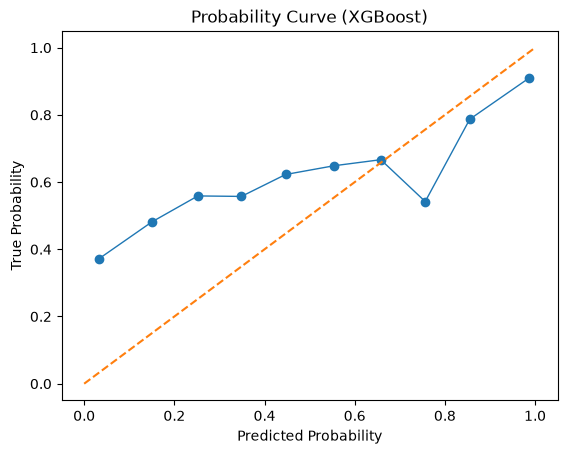

In [101]:
# Calibration curve

prob_pos = xgb_model.predict_proba(X_test)[:, 1]
true_pos, pred_pos = calibration_curve(y_test, prob_pos, n_bins=10)

plt.plot(pred_pos, true_pos, marker='o', linewidth=1, label='Logistic Regression')
plt.plot([0, 1], [0, 1], linestyle='--')

plt.title('Probability Curve (XGBoost)')
plt.xlabel('Predicted Probability')
plt.ylabel('True Probability')

# How to interpret the plot:
# X-axis: Model’s predicted probabilities
# Y-axis: Actually observed frequencies
# Gray dashed line: Perfect calibration (predicted = observed)
# Blue line: Model’s calibration curve
